# 02 분석 코호트 확정
다운로드·임베딩된 대표 슬라이드 751장으로 분석 코호트 표(슬라이드–환자–암종–기관–fold–타일 수)를 만든다. 
- 커널: `C:\Users\Admin\EXAONEPath\exaonepath-venv`
- 출력: `C:\Users\Admin\EXAONEPath_data\v4\02_cohort\{cohort.csv, excluded_slides.csv}`

In [4]:
# 1. 경로
from pathlib import Path
import pandas as pd

V3   = Path(r"C:\Users\Admin\EXAONEPath_data\v3")
OUT1 = Path(r"C:\Users\Admin\EXAONEPath_data\v4\01_inventory")
OUT  = Path(r"C:\Users\Admin\EXAONEPath_data\v4\02_cohort")
OUT.mkdir(parents=True, exist_ok=True)

In [2]:
# 2. 슬라이드 상태 + 기관 단위 fold
co = pd.read_csv(OUT1 / "slides_status.csv")
folds = pd.concat([pd.read_csv(V3 / "splits" / f"{c}_folds.csv") for c in ("luad", "lusc")])
print("folds 열:", folds.columns.tolist())  # patient_id, fold 가정
co = co.merge(folds[["patient_id", "fold"]].drop_duplicates("patient_id"), on="patient_id", how="left")
co["excluded"] = co.n_tiles.le(0).map({True: "조직 타일 0개", False: ""})

folds 열: ['patient_id', 'slide_id', 'tss', 'fold']


In [3]:
# 3. 저장과 요약
co.to_csv(OUT / "cohort.csv", index=False, encoding="utf-8-sig")
co[co.excluded != ""].to_csv(OUT / "excluded_slides.csv", index=False, encoding="utf-8-sig")
inc = co[co.excluded == ""]
print(co.groupby("cancer").agg(slides=("slide_id", "size"), included=("excluded", lambda x: int((x == "").sum())),
                               tss=("tss", "nunique"), no_fold=("fold", lambda x: int(x.isna().sum()))))
pd.crosstab(inc.cancer, inc.fold)

        slides  included  tss  no_fold
cancer                                
LUAD       404       403   33        0
LUSC       347       347   34        0


fold,0,1,2,3,4
cancer,,,,,
LUAD,89,80,78,78,78
LUSC,71,68,68,70,70


여러 fold에 걸친 기관 수: 0


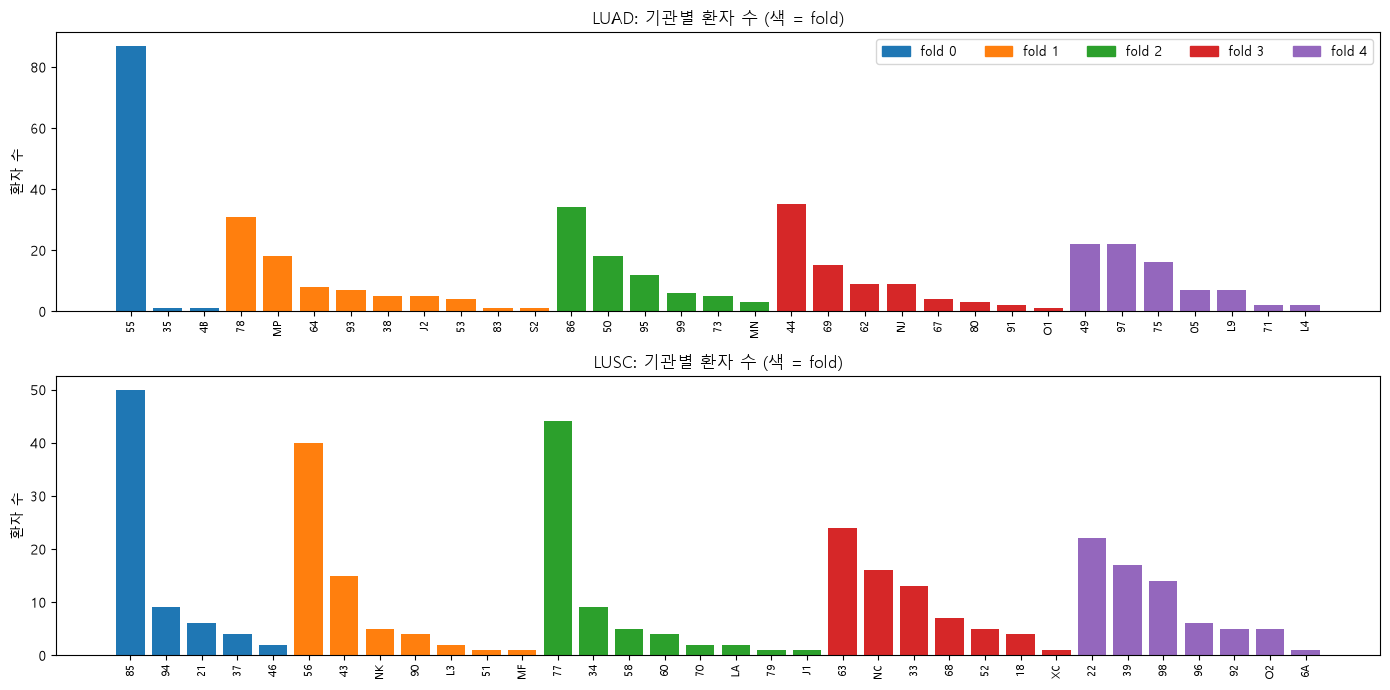

In [5]:
# 4. 기관별 환자 수 (색 = fold)
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"

print("여러 fold에 걸친 기관 수:", int((inc.groupby(["cancer", "tss"]).fold.nunique() > 1).sum()))  # 0이어야 기관 단위 분할

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
for ax, (c, d) in zip(axes, inc.groupby("cancer")):
    n = d.groupby(["fold", "tss"]).size().reset_index(name="n").sort_values(["fold", "n"], ascending=[True, False])
    ax.bar(range(len(n)), n.n, color=[f"C{f}" for f in n.fold])
    ax.set_xticks(range(len(n)), n.tss.astype(str), rotation=90, fontsize=8)
    ax.set_title(f"{c}: 기관별 환자 수 (색 = fold)"); ax.set_ylabel("환자 수")
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=f"C{f}") for f in range(5)], [f"fold {f}" for f in range(5)], ncol=5)
fig.tight_layout()
fig.savefig(OUT / "fold_by_tss.png", dpi=150)